# 03 · Signatures — embryonic-development module scores & Gate 2

Render each cell's score for the three embryonic modules (**Gast** gastrulation,
**pSom** posterior somitogenesis, **Crest** neural crest), scored in step 02 with
`score_genes` against the shared **union** control pool and graph-smoothed (the 10x
precedent — raw per-cell 10x scores are dropout-dominated). Then evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom
into *distinct arms* with Crest as a terminal readout. A non-branching manifold
instead shows a **shared developmental gradient**: the two embryonic-origin
programs occupy the trajectory origin (they overlap rather than resolving into two
competing arms), and Crest occupies the opposite (terminal) end as an inverse
gradient. If that pattern is present, **Gate 2 = GO**; with no bifurcation the
cross-repression test is **Gate 3 = NA**. Deliverable: `signatures.h5ad`,
`{Gast,pSom,Crest}_signature.pdf` + colorbars.

**Layout note.** The Chen malignant manifold is a roundish cloud (UMAP aspect
ratio ~1.4), not an elongated strip, so the signature panels use square (5,5)
axes — the Puram 03 layout, and consistent with this run's `manifold.pdf` /
`samples.pdf` — rather than the wide-short linear layout used for a strip-shaped
manifold. Orientation matches `manifold.pdf` (developmental origin left, Crest
terminus right); no axis inversion is applied.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name)

dataset: Chen2020_Head-and-Neck-5


### Load the rooted manifold (signatures already scored + smoothed in 02)
Confirm gene coverage for the record, then read the smoothed scores.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast': 'Gastrulation Signature',
           'pSom': 'Somitogenesis Signature',
           'Crest': 'Neural Crest Signature'}
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.n_obs, '| smoothed scores present:',
      [m + '_sm' for m in modules if m + '_sm' in adata.obs])

Gast: 73/81 genes present
pSom: 91/98 genes present
Crest: 99/104 genes present
cells: 3635 | smoothed scores present: ['Gast_sm', 'pSom_sm', 'Crest_sm']


### Gate 2 — module geography on the manifold (shown, not asserted)
Quantitative test of the non-branching signature on the smoothed scores:
(i) do the two embryonic-origin programs share territory rather than splitting into
opposed arms, (ii) is Crest spatially anti-correlated with both, (iii) along
pseudotime do Gast/pSom sit at the origin while Crest rises to the terminus.

In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t - t.min()) / (t.max() - t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
print('high-decile mean pseudotime (terminal if ~1, origin if ~0):')
for s in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    hi = adata.obs[s] >= adata.obs[s].quantile(0.9)
    print(f'  {s}: {tn[hi.values].mean():.2f}')
print()
print('Gast/pSom co-localize at the origin (no competing arms; Gast~pSom r~0 => no cross-repression),')
print('Crest is the inverse terminal gradient -> Gate 2 = GO (non-branching); Gate 3 = NA (no bifurcation).')
print('Note: pSom dynamic range is small on this 10x dataset (weak module), but it sits at the origin end, not opposed to Gast.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.00
  Crest_sm vs Gast_sm: r = -0.78
  Crest_sm vs pSom_sm: r = -0.42
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.785
  pSom_sm: rho = -0.214
  Crest_sm: rho = +0.816
high-decile mean pseudotime (terminal if ~1, origin if ~0):
  Gast_sm: 0.22
  pSom_sm: 0.22
  Crest_sm: 0.97

Gast/pSom co-localize at the origin (no competing arms; Gast~pSom r~0 => no cross-repression),
Crest is the inverse terminal gradient -> Gate 2 = GO (non-branching); Gate 3 = NA (no bifurcation).
Note: pSom dynamic range is small on this 10x dataset (weak module), but it sits at the origin end, not opposed to Gast.


### Three-panel overview (module geography at a glance)
Origin (left) → Crest terminus (right); plasma; smoothed scores.

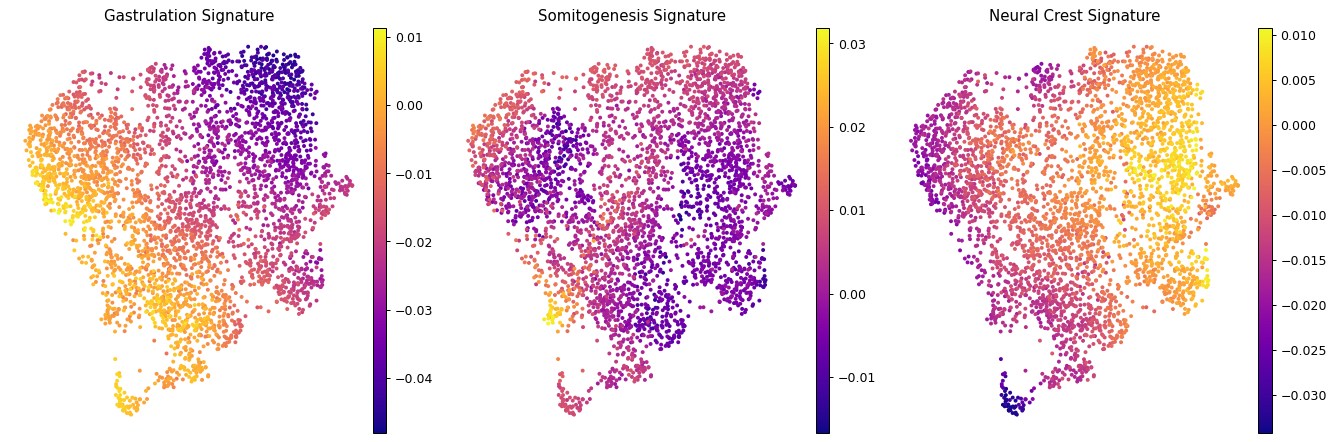

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(adata, color=m + '_sm', cmap='plasma', size=40, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
fig.tight_layout()

### Per-module signature figures + colorbars (deliverable)
Puram 03 layout: square (5,5) panel, plasma, smoothed score, developmental
milestones overlaid on data, external colorbar with data-driven ticks. Orientation
follows `manifold.pdf` (origin left → terminus right); no axis inversion.

<cell 6>:14: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 6>:14: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 6>:14: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


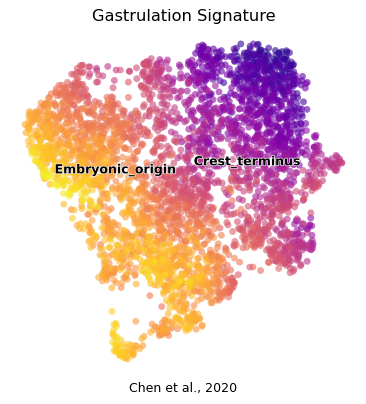

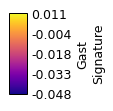

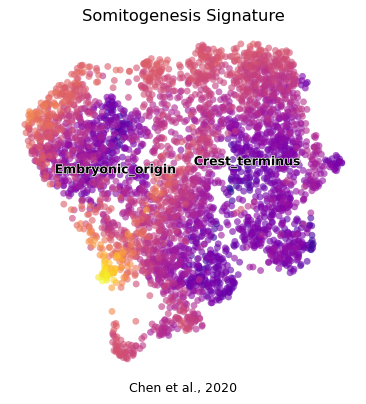

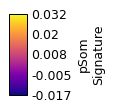

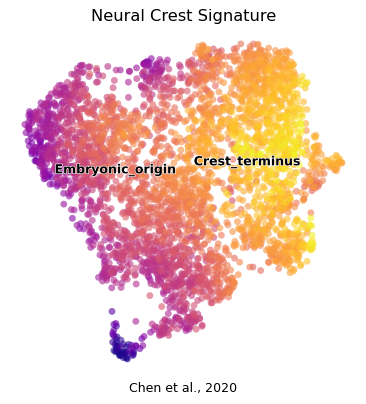

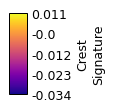

In [6]:
for lab, title in modules.items():
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    sc.pl.umap(adata, color=lab + '_sm', cmap='plasma', alpha=.6, size=120,
               colorbar_loc=None, frameon=False, show=False, ax=ax)
    sc.pl.umap(adata, color='milestones', size=120, alpha=0, legend_loc='on data',
               legend_fontoutline=1, frameon=False, show=False, ax=ax)
    ax.set_title(title, size=13)
    ax.text(.5, -.05, 'Chen et al., 2020', ha='center', transform=ax.transAxes)
    fig.savefig(os.path.join(pth_fig, f'{lab}_signature.pdf'), bbox_inches='tight')

    lo, hi = float(adata.obs[lab + '_sm'].min()), float(adata.obs[lab + '_sm'].max())
    ticks = np.round(np.linspace(lo, hi, 5), 3)
    fcb = plt.figure(figsize=(.66, 1)); cax = fcb.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{lab}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{lab}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{lab}_signature.pdf', '+ colorbar')

### Save signatures data

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3635, 22080)
